<a href="https://colab.research.google.com/github/Lerreto/Inpainting-Numerical-Project-2026/blob/pedro/impaiting_pedro_marin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Image Inpainting Restoration Problem**

Image inpainting is an inverse problem in which an observed image $\mathbf{y}$ contains missing pixels from a clean image $\mathbf{x}$:

$$
\mathbf{y}=\mathbf{m}\odot\mathbf{x},
$$

where $\mathbf{m}\in\{0,1\}^{H\times W}$ is a binary mask and $\odot$ denotes element-wise multiplication. In this baseline, each pixel is retained with probability $0.8$; therefore approximately $20\%$ of the spatial samples are removed. Training masks are resampled online, while validation/test masks are deterministic per image.

### **Objective**
Develop a deep-learning model that estimates $\hat{\mathbf{x}}=f_\theta(\mathbf{y})$ from corrupted observations with missing pixels.

### **Experimental protocol**
- Dataset: BSDS500, matching the other image-restoration projects.
- Training crops: $96\times96$ with random crop and horizontal flip.
- Validation crop: centered $288\times288$.
- Fixed corruption level: pixel retention probability $p=0.8$ (approximately $20\%$ missing samples).
- Training masks are resampled online; validation/test masks are deterministic per image.
- Backbone: same compact residual CNN family used in the other projects.
- Loss: MSE by default.
- Metrics: PSNR and SSIM.
- Validation uses inference mode and the best validation checkpoint is restored.
- The corrupted input itself is reported as a baseline.

### **Activities**
1. Improve the baseline performance by changing optimization, loss, capacity, augmentation, or architecture.
2. Compare the restored result against the corrupted-input baseline.
3. Document quantitative and visual results in an academic report.


# **Improvement Difficulty Levels**

To improve the baseline model, use the following difficulty guide.

## **Fixed components (cannot be changed)**
- **Dataset:** keep the BSDS500 dataset exactly as provided.
- **Corruption process:** keep the provided inpainting corruption process fixed. Do not remove it, replace it, or redesign it.

## **Allowed modifications**
You may improve the model by modifying the training pipeline and/or the neural network, for example:
- hyperparameter tuning
- preprocessing choices
- optimizer and learning-rate strategy
- loss function
- regularization
- weight initialization
- neural network architecture

## **Level 1 — Easy**
Focus on **hyperparameter tuning**. Examples:
- change batch size
- change the number of epochs
- change the learning rate
- change the number of filters
- change the number of residual blocks

## **Level 2 — Medium**
Modify the **training recipe** while keeping the general baseline architecture. Examples:
- compare optimizers (Adam, AdamW, RMSprop, etc.)
- test different losses (MSE, MAE/L1, weighted combinations)
- add regularization such as weight decay or dropout if justified
- improve preprocessing or data augmentation
- test learning-rate scheduling

## **Level 3 — Hard**
Modify the **neural network architecture**. Examples:
- deepen the network
- widen the network
- redesign the residual blocks
- add skip connections
- build a different CNN restoration architecture for the same task

## **Recommendation**
Start with a Level 1 improvement, verify whether PSNR/SSIM improve, and then move to Level 2 or Level 3 if needed. For every modification, explain **what changed**, **why it may help**, and **how the metrics and restored images changed**.


In [1]:
#@title Import libraries and set reproducibility
!pip -q install torchmetrics

import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.optim import SGD, Adam, RMSprop
from torchmetrics.functional.image import peak_signal_noise_ratio
from torchmetrics.functional.image import structural_similarity_index_measure
from torch.optim.lr_scheduler import CosineAnnealingLR
import torch.optim as optim

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 29.4 MB/s eta 0:00:00
Device: cuda:0


In [2]:
#@title Download BSDS500 Training and Validation Dataset
# Same dataset source used by the original Super-Resolution and Inpainting notebooks.
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC" -O BSDS500.zip && rm -rf /tmp/cookies.txt
!mkdir -p /content/BSDS500
!unzip -q -o BSDS500.zip -d /content/BSDS500

print('Dataset folders:', os.listdir('/content/BSDS500'))


--2026-10-21 18:36:52--  https://docs.google.com/uc?export=download&confirm=&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC
Resolving docs.google.com (docs.google.com)... 172.217.218.113, 172.217.218.138, 172.217.218.101, ...
Connecting to docs.google.com (docs.google.com)|172.217.218.113|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC&export=download [following]
--2026-10-21 18:36:52--  https://drive.usercontent.google.com/download?id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 192.178.156.132, 2a00:1450:4013:c1c::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|192.178.156.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22232532 (21M) [application/octet-stream]
Saving to: ‘BSDS500.zip’

BSDS500.zip         100%[===================>]  21.20M   

In [3]:
#@title Utility functions
class AverageMeter:
    def __init__(self):
        self.reset()

    def reset(self):
        self.avg = 0.0
        self.sum = 0.0
        self.count = 0

    def update(self, val, n=1):
        self.sum += float(val) * n
        self.count += n
        self.avg = self.sum / max(self.count, 1)


def read_rgb_file(filename):
    return Image.open(filename).convert('RGB')


def compute_metrics(pred, target):
    # Metrics are evaluated in the physical image range [0, 1].
    pred = pred.clamp(0.0, 1.0)
    target = target.clamp(0.0, 1.0)
    psnr = peak_signal_noise_ratio(pred, target, data_range=1.0)
    ssim = structural_similarity_index_measure(pred, target, data_range=1.0)
    return psnr.item(), ssim.item()


def show_tensor(img, ax=None, title=None):
    img = img.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy()
    if ax is None:
        plt.imshow(img)
        plt.axis('off')
        if title:
            plt.title(title)
    else:
        ax.imshow(img)
        ax.axis('off')
        if title:
            ax.set_title(title)


In [4]:
#@title Random-mask corruption (fixed inverse problem)
class CorruptionProcess:
    def __init__(self, keep_probability=0.8, train=False, seed=1234):
        self.keep_probability = float(keep_probability)
        self.train = train
        self.seed = int(seed)
        if not (0.0 < self.keep_probability <= 1.0):
            raise ValueError('keep_probability must be in (0, 1]')

    def __call__(self, x, idx=None):
        # x: (C, H, W), CPU tensor in [0,1]
        h, w = x.shape[-2:]
        if self.train:
            random_map = torch.rand((1, h, w), dtype=x.dtype)
        else:
            # Deterministic validation/test mask for reproducible metrics.
            g = torch.Generator().manual_seed(self.seed + int(idx or 0))
            random_map = torch.rand((1, h, w), generator=g, dtype=x.dtype)
        mask = (random_map < self.keep_probability).to(x.dtype)
        return x * mask

KEEP_PROBABILITY = 0.80  # fixed for the baseline experiment


In [5]:
#@title Dataset loader
class PairedRestorationDataset(Dataset):
    def __init__(self, data_path, transform, corruption):
        self.data_path = data_path
        self.imgs_names = sorted([
            f for f in os.listdir(data_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        self.transform = transform
        self.corruption = corruption

    def __len__(self):
        return len(self.imgs_names)

    def __getitem__(self, idx):
        path = os.path.join(self.data_path, self.imgs_names[idx])
        x = self.transform(read_rgb_file(path))
        y = self.corruption(x, idx)
        return x, y


def load_data(data_path, batch_size=4, train_size=96, val_size=288):
    train_transform = transforms.Compose([
        transforms.RandomCrop(train_size),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
    ])
    eval_transform = transforms.Compose([
        transforms.CenterCrop(val_size),
        transforms.ToTensor(),
    ])

    train_corruption = CorruptionProcess(KEEP_PROBABILITY, train=True, seed=SEED)
    eval_corruption = CorruptionProcess(KEEP_PROBABILITY, train=False, seed=SEED + 10000)

    train_dir = os.path.join(data_path, 'train')
    val_dir = os.path.join(data_path, 'val')
    test_dir = os.path.join(data_path, 'test')

    train_ds = PairedRestorationDataset(train_dir, train_transform, train_corruption)
    val_ds = PairedRestorationDataset(val_dir, eval_transform, eval_corruption)
    test_ds = PairedRestorationDataset(test_dir, eval_transform, eval_corruption) if os.path.isdir(test_dir) else None

    loader_kwargs = dict(num_workers=2, pin_memory=torch.cuda.is_available())
    g = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g, **loader_kwargs)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, **loader_kwargs) if test_ds is not None else None
    return train_loader, val_loader, test_loader


## What did we add in the DNN?

We added skip connections in the forward of the DNN, previously it did skip connections in only the residual block, but we decided to also add it to the whole neural network.

In [6]:
#@title Deep Neural Network Architecture
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=True)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=True)

    def forward(self, x):
        residual = x
        out = self.relu(self.conv1(x))
        out = self.conv2(out)
        return out + residual


class DeepNeuralNetwork(nn.Module):
    """Same compact restoration backbone used by the inpainting baseline."""
    def __init__(self, num_channels=3, base_filter=16, num_residuals=4):
        super().__init__()
        self.conv1 = nn.Conv2d(
            num_channels, base_filter, kernel_size=3, stride=1,
            padding=1, bias=True, padding_mode='reflect'
        )
        self.relu = nn.ReLU(inplace=True)
        self.residuals = nn.Sequential(*[
            ResidualBlock(base_filter, base_filter)
            for _ in range(num_residuals)
        ])
        self.conv2 = nn.Conv2d(base_filter, num_channels, kernel_size=1, stride=1, padding=0, bias=True)

    def forward(self, x):
        feat = self.relu(self.conv1(x))
        out = self.residuals(feat) + feat
        out = self.conv2(out)
        return out + x


## What did we add?

For testing purposes, we added the AdamW (Adam with weight decay) optimizer and the RMSE cost function (Root Mean Square Error).

We added early stopping, with a new variable called 'patiente', this variable's purpose is to stop the training if the model can't find a better val_loss in a number of epochs determined by the variable, this allows to increase the number of epochs but allow it to stop whenever the val_loss converges.

We also changed the weight decay of the optimizers to 1e-6, since the previous value (1e-9) was too low for most optimizers, especially Adam and AdamW.

## Why didn't we stick with only modifying the hyperparameters?

Although by only modifying the hyperparameters we were able to get really good results, we weren't satisfied, we had two main reasons to do this:

* Getting good results required increasing the hyperparameters, however, by doing this, the computational costs increased exponentially, which in real life usage could result in a downside.
* We didn't like the idea of sticking to only changing hyperparameters, we knew we could achieve better results by changing the way the training worked (and, if needed, changing the CNN architecture), this as a side effect would allow to not having to increase the computational cost of the DNN to have better results.

In [17]:
#@title Model hyperparameters, optimizer, and loss
EPOCHS = 300 #@param
BATCH_SIZE = 4 #@param

patience = 30 #@param
base_filter = 16 #@param
num_residuals = 10 #@param

model = DeepNeuralNetwork(base_filter=base_filter, num_residuals=num_residuals).to(device)

optimizer_name = 'AdamW' #@param ["SGD", "Adam", "RMSprop", "AdamW"] {type:"string"}
cost_function = 'MAE' #@param ["MSE", "MAE", "RMSE"] {type:"string"}
learning_rate = 2e-3 #@param

if optimizer_name == 'SGD':
    optimizer = SGD(model.parameters(), lr=learning_rate, momentum=0.9, weight_decay=1e-6)
elif optimizer_name == 'Adam':
    optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=1e-6)
elif optimizer_name == 'RMSprop':
    optimizer = RMSprop(model.parameters(), lr=learning_rate, weight_decay=1e-6)
elif optimizer_name == 'AdamW':
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-6)
else:
    raise ValueError('Unknown optimizer')


if cost_function == 'MSE' or cost_function == 'RMSE':
  criterion = nn.MSELoss()
elif cost_function == 'MAE':
  criterion = nn.L1Loss()
else:
  raise ValueError('Unknown cost function')

scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {n_params:,}')

CHECKPOINT_PATH = "/content/best_inpainting_model.pt"
print(f"Optimizer: {optimizer_name}")
print(f"Cost function: {cost_function}")


Trainable parameters: 46,899
Optimizer: AdamW
Cost function: MAE


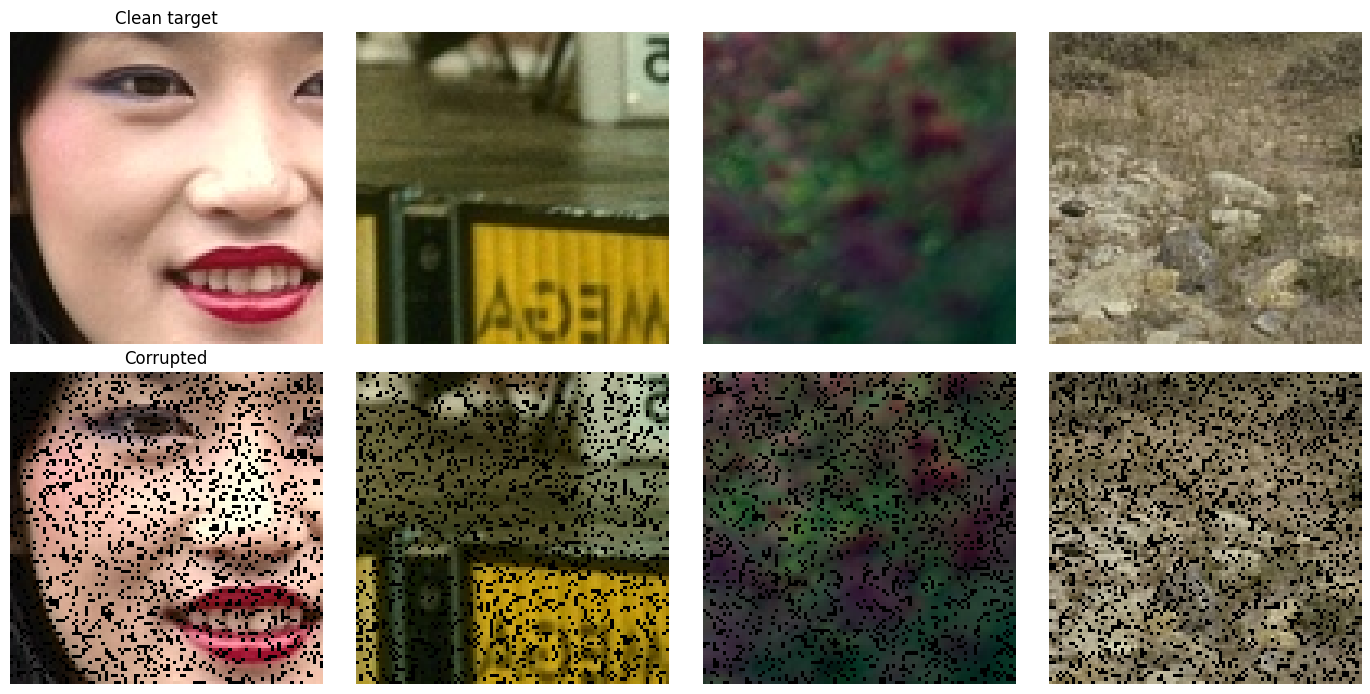

Pixel retention probability: 0.80 | Missing samples: 20%
Train batches: 50 | Validation images: 100
Independent test set: not available in this dataset package


In [8]:
#@title Load dataset and visualize samples
data_path = '/content/BSDS500'
train_loader, val_loader, test_loader = load_data(data_path, batch_size=BATCH_SIZE)

x, y = next(iter(train_loader))
num_imgs = min(4, x.size(0))
fig, axs = plt.subplots(2, num_imgs, figsize=(14, 7))
for i in range(num_imgs):
    show_tensor(x[i], axs[0, i], 'Clean target' if i == 0 else None)
    show_tensor(y[i], axs[1, i], 'Corrupted' if i == 0 else None)
plt.tight_layout()
plt.show()

print(f'Pixel retention probability: {KEEP_PROBABILITY:.2f} | Missing samples: {(1-KEEP_PROBABILITY)*100:.0f}%')
print('Train batches:', len(train_loader), '| Validation images:', len(val_loader))
print('Independent test set:', 'available' if test_loader is not None else 'not available in this dataset package')


In [15]:
#@title Baseline vs restored-image evaluation
def evaluate(loader, model=None):
    loss_m, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

    if model is not None:
        model.eval()

    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            pred = y if model is None else model(y)
            if cost_function == 'RMSE':
              loss = torch.sqrt(criterion(pred,x))
            else:
              loss = criterion(pred, x)
            psnr_val, ssim_val = compute_metrics(pred, x)

            n = x.size(0)
            loss_m.update(loss.item(), n)
            psnr_m.update(psnr_val, n)
            ssim_m.update(ssim_val, n)

    return {'loss': loss_m.avg, 'psnr': psnr_m.avg, 'ssim': ssim_m.avg}

# Baseline before training (validation)
baseline_pre = evaluate(val_loader, model=None)
print(f"Corrupted-input validation baseline | PSNR {baseline_pre['psnr']:.2f} dB | SSIM {baseline_pre['ssim']:.3f}")


Corrupted-input validation baseline | PSNR 13.54 dB | SSIM 0.278


In [16]:
#@title Training process with validation and best-model checkpoint
count = 0
history = {
    'train_loss': [], 'train_psnr': [], 'train_ssim': [],
    'val_loss': [], 'val_psnr': [], 'val_ssim': []
}

best_val_psnr = -float('inf')
best_state = None

for epoch in range(EPOCHS):
    count+=1

    if count<patience:
      losses, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()
      val_losses, val_psnr_m, val_ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

      model.train()
      for x, y in train_loader:
          x = x.to(device, non_blocking=True)
          y = y.to(device, non_blocking=True)

          optimizer.zero_grad(set_to_none=True)
          x_hat = model(y)
          loss = criterion(x_hat, x)
          loss.backward()
          optimizer.step()

          with torch.no_grad():
              psnr_val, ssim_val = compute_metrics(x_hat, x)

          n = x.size(0)
          losses.update(loss.item(), n)
          psnr_m.update(psnr_val, n)
          ssim_m.update(ssim_val, n)

      model.eval()
      with torch.inference_mode():
          for x, y in val_loader:
              x = x.to(device, non_blocking=True)
              y = y.to(device, non_blocking=True)
              x_hat = model(y)

              loss = criterion(x_hat, x)
              psnr_val, ssim_val = compute_metrics(x_hat, x)

              n = x.size(0)
              val_losses.update(loss.item(), n)
              val_psnr_m.update(psnr_val, n)
              val_ssim_m.update(ssim_val, n)

      history['train_loss'].append(losses.avg)
      history['train_psnr'].append(psnr_m.avg)
      history['train_ssim'].append(ssim_m.avg)
      history['val_loss'].append(val_losses.avg)
      history['val_psnr'].append(val_psnr_m.avg)
      history['val_ssim'].append(val_ssim_m.avg)

      scheduler.step()

      if val_psnr_m.avg > best_val_psnr:
          count=0
          best_val_psnr = val_psnr_m.avg
          best_state = copy.deepcopy(model.state_dict())
          torch.save(best_state, CHECKPOINT_PATH)
          print(
          f'New best PSNR at Epoch {epoch+1:03d}/{EPOCHS} | '
          f'Loss {losses.avg:.7f} | PSNR {psnr_m.avg:.2f} | SSIM {ssim_m.avg:.3f} | '
          f'Val Loss {val_losses.avg:.7f} | Val PSNR {val_psnr_m.avg:.2f} | Val SSIM {val_ssim_m.avg:.3f}'
          )
    else:
      print(f"There wasn't a better value after {count} epochs, stopping training")
      break

model.load_state_dict(best_state)
print(f'Best validation PSNR: {best_val_psnr:.2f} dB')
print('Best checkpoint:', CHECKPOINT_PATH)


New best PSNR at Epoch 001/300 | Loss 0.0863075 | PSNR 18.87 | SSIM 0.440 | Val Loss 0.0380350 | Val PSNR 24.71 | Val SSIM 0.678
New best PSNR at Epoch 002/300 | Loss 0.0339210 | PSNR 25.01 | SSIM 0.693 | Val Loss 0.0253845 | Val PSNR 27.37 | Val SSIM 0.803
New best PSNR at Epoch 003/300 | Loss 0.0244812 | PSNR 26.94 | SSIM 0.800 | Val Loss 0.0228712 | Val PSNR 28.52 | Val SSIM 0.854
New best PSNR at Epoch 004/300 | Loss 0.0212858 | PSNR 27.83 | SSIM 0.823 | Val Loss 0.0169290 | Val PSNR 29.91 | Val SSIM 0.881
New best PSNR at Epoch 005/300 | Loss 0.0168462 | PSNR 29.11 | SSIM 0.867 | Val Loss 0.0174432 | Val PSNR 30.04 | Val SSIM 0.887
New best PSNR at Epoch 006/300 | Loss 0.0168775 | PSNR 29.24 | SSIM 0.867 | Val Loss 0.0161573 | Val PSNR 30.09 | Val SSIM 0.894
New best PSNR at Epoch 007/300 | Loss 0.0157980 | PSNR 29.59 | SSIM 0.884 | Val Loss 0.0157204 | Val PSNR 30.69 | Val SSIM 0.905
New best PSNR at Epoch 008/300 | Loss 0.0132259 | PSNR 30.58 | SSIM 0.900 | Val Loss 0.0131722 | 

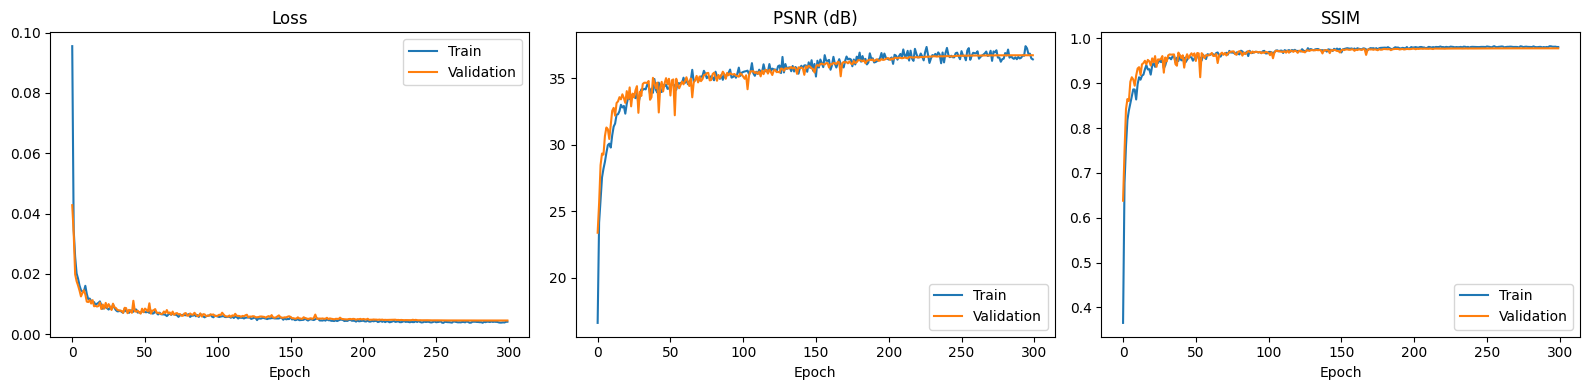

In [11]:
#@title Training curves
fig, axs = plt.subplots(1, 3, figsize=(16, 4))

axs[0].plot(history['train_loss'], label='Train')
axs[0].plot(history['val_loss'], label='Validation')
axs[0].set_title('Loss')
axs[0].set_xlabel('Epoch')
axs[0].legend()

axs[1].plot(history['train_psnr'], label='Train')
axs[1].plot(history['val_psnr'], label='Validation')
axs[1].set_title('PSNR (dB)')
axs[1].set_xlabel('Epoch')
axs[1].legend()

axs[2].plot(history['train_ssim'], label='Train')
axs[2].plot(history['val_ssim'], label='Validation')
axs[2].set_title('SSIM')
axs[2].set_xlabel('Epoch')
axs[2].legend()

plt.tight_layout()
plt.show()


In [12]:
#@title Baseline vs restored-image evaluation
def evaluate(loader, model=None):
    loss_m, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

    if model is not None:
        model.eval()

    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            pred = y if model is None else model(y)
            loss = criterion(pred, x)
            psnr_val, ssim_val = compute_metrics(pred, x)

            n = x.size(0)
            loss_m.update(loss.item(), n)
            psnr_m.update(psnr_val, n)
            ssim_m.update(ssim_val, n)

    return {'loss': loss_m.avg, 'psnr': psnr_m.avg, 'ssim': ssim_m.avg}

final_loader = test_loader if test_loader is not None else val_loader
final_split = 'TEST' if test_loader is not None else 'VALIDATION (no independent test folder found)'

baseline = evaluate(final_loader, model=None)
restored = evaluate(final_loader, model=model)

print(final_split)
print(f"Input baseline  | Loss {baseline['loss']:.7f} | PSNR {baseline['psnr']:.2f} dB | SSIM {baseline['ssim']:.3f}")
print(f"Restored model  | Loss {restored['loss']:.7f} | PSNR {restored['psnr']:.2f} dB | SSIM {restored['ssim']:.3f}")
print(f"PSNR gain       | {restored['psnr'] - baseline['psnr']:+.2f} dB")


VALIDATION (no independent test folder found)
Input baseline  | Loss 0.0851477 | PSNR 13.54 dB | SSIM 0.278
Restored model  | Loss 0.0045540 | PSNR 36.73 dB | SSIM 0.978
PSNR gain       | +23.19 dB


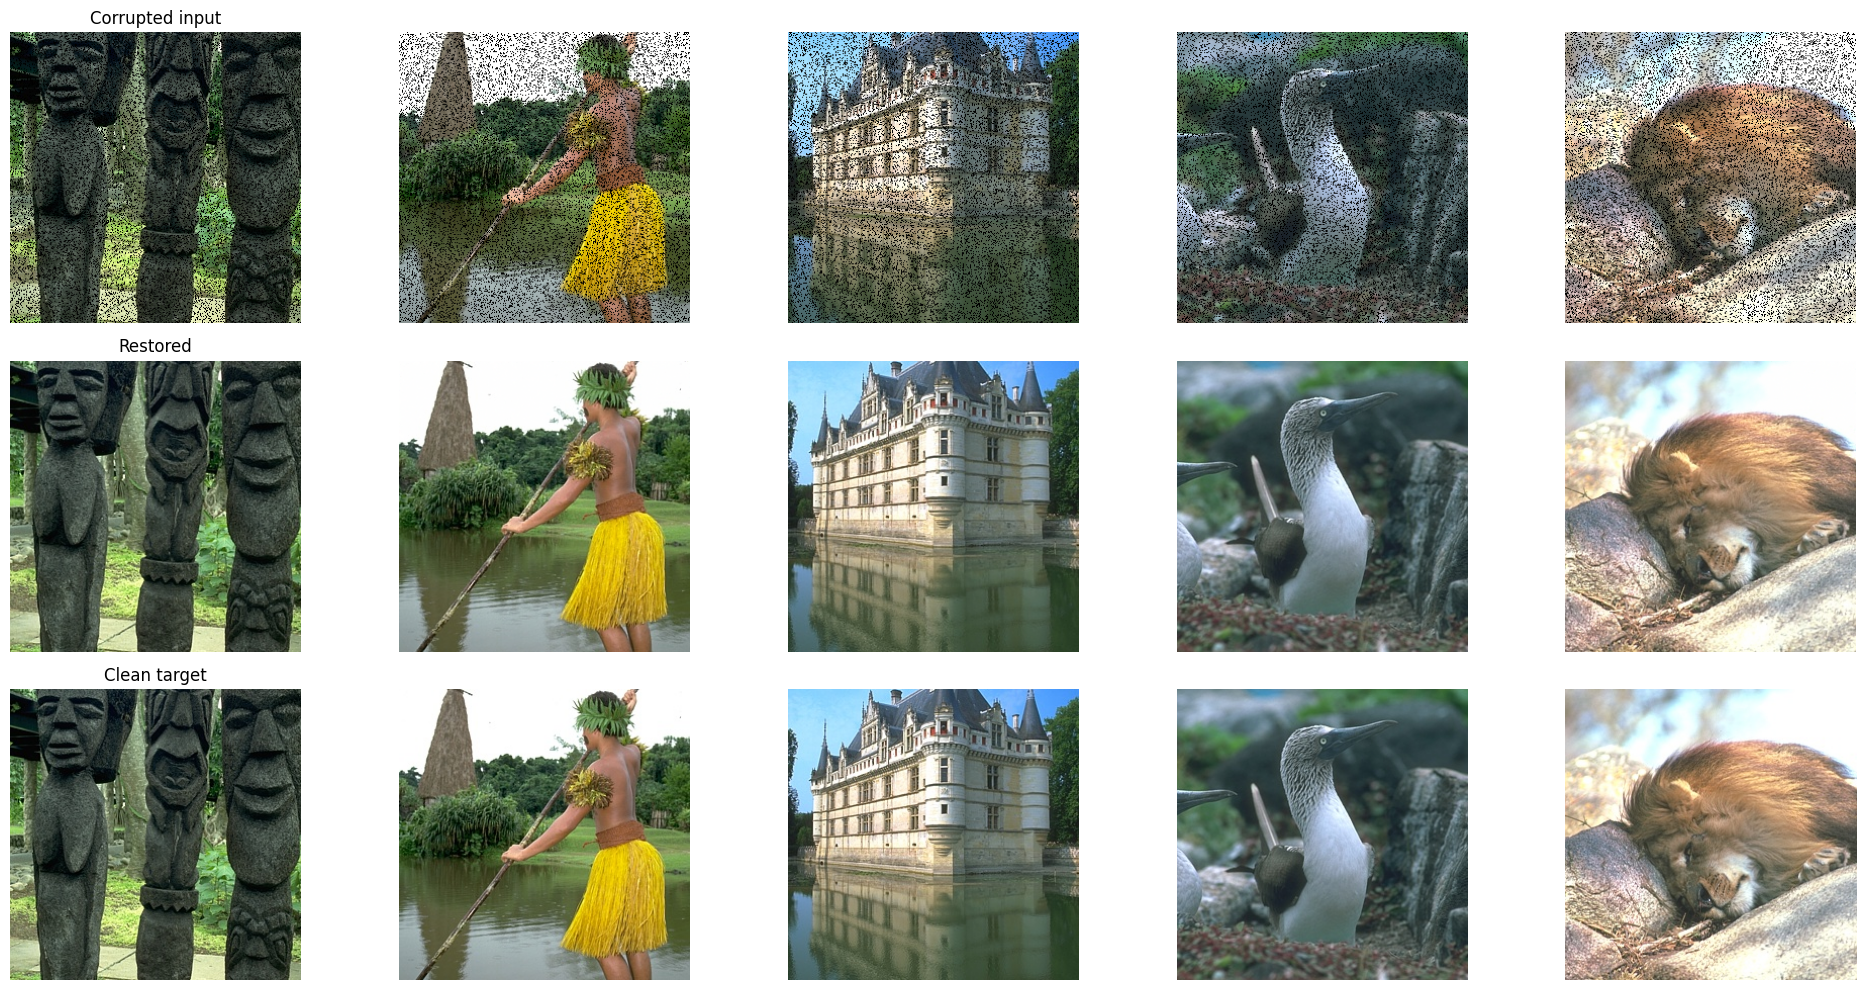

In [13]:
#@title Visual inference
loader = test_loader if test_loader is not None else val_loader
num_images = min(5, len(loader))
fig, axs = plt.subplots(3, num_images, figsize=(4*num_images, 10))
axs = np.array(axs).reshape(3, num_images)

model.eval()
with torch.inference_mode():
    for i, (x, y) in enumerate(loader):
        if i >= num_images:
            break
        pred = model(y.to(device)).cpu().clamp(0, 1)
        show_tensor(y[0], axs[0, i], 'Corrupted input' if i == 0 else None)
        show_tensor(pred[0], axs[1, i], 'Restored' if i == 0 else None)
        show_tensor(x[0], axs[2, i], 'Clean target' if i == 0 else None)

plt.tight_layout()
plt.show()
